# Khảo sát dữ liệu ViPRA
Chạy từ trên xuống. Notebook chỉ đọc dữ liệu gốc.

Thư viện: `pandas`, `matplotlib`, `transformers`, `sentencepiece`, `jinja2`.
Nếu thiếu, chạy trong một ô: `%pip install pandas matplotlib transformers sentencepiece jinja2`.


## 1. Đọc dữ liệu
Đổi `DATA_DIR` khi chuyển dataset. Tokenizer dưới đây là **ví dụ**; đổi theo mô hình sẽ fine-tune.
Chỉ tải tokenizer, không tải trọng số LLM.


In [1]:
from pathlib import Path
import json, re, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

DATA_DIR = Path("/Users/nho/Downloads/datasets")
FILES = {"train": "train_dataset.csv", "dev": "dev_dataset.csv"}
TOKENIZER_ID = "Qwen/Qwen2.5-7B-Instruct"
LIMITS = [1024, 2048, 4096]
COLS = ["id", "question", "cot", "answer", "unit"]

frames = {}
for split, filename in FILES.items():
    df = pd.read_csv(DATA_DIR / filename, dtype=str, keep_default_na=False)
    if missing := set(COLS) - set(df.columns):
        raise ValueError(f"{filename} thiếu cột: {sorted(missing)}")
    frames[split] = df[COLS].copy()
data = pd.concat([df.assign(split=s) for s, df in frames.items()], ignore_index=True)
display(data.groupby("split").size().rename("Số mẫu").to_frame())
display(data[COLS + ["split"]].head(3))


,Số mẫu
split,
dev,339
train,677


,id,question,cot,answer,unit,split
0,CH257,"Mạch nối tiếp X_L = 22 Ω, X_C = 198 Ω, U = 110...",1. Nhận diện dữ kiện:\n- Mạch nối tiếp gồm điệ...,110,V,train
1,CH259,"Đoạn mạch với X_L = 35 Ω, X_C = 140 Ω, U = 180...","1. Nhận diện dữ kiện:\n- X_L = 35 Ω, X_C = 140...",180,V,train
2,NL326,"Trong một thí nghiệm, người ta đo được điện nă...",1. Nhận diện dữ kiện:\n- Điện năng tiêu tán (W...,90,%,train


## 2. Trường rỗng và ID
Đếm cả chuỗi chỉ có khoảng trắng. `unit` rỗng có thể hợp lệ; đáp án `0` không phải dữ liệu thiếu.


In [2]:
empty = data[COLS].apply(lambda s: s.str.strip().eq(""))
display(empty.groupby(data["split"]).sum().T.rename_axis("Cột rỗng"))
display(data.groupby("split")["id"].agg(total="size", unique="nunique"))
escaped = data[["question", "cot"]].apply(lambda s: s.str.contains("\\n", regex=False))
display(escaped.groupby(data["split"]).sum().T.rename_axis("Chứa ký tự \\n thay vì xuống dòng"))


split,dev,train
Cột rỗng,,
id,0,0
question,0,0
cot,0,0
answer,0,1
unit,2,5


,total,unique
split,,
dev,339,339
train,677,677


split,dev,train
Chứa ký tự \n thay vì xuống dòng,,
question,0,0
cot,0,0


## 3. Trùng và nhãn khác nhau
Khóa câu hỏi chỉ chuẩn hóa Unicode NFC và khoảng trắng, giữ nguyên chữ hoa/thường.
Các con số đếm **mọi dòng tham gia nhóm trùng**, không chỉ số dòng dư.
Nhãn khác nhau là dấu hiệu cần đọc lại, chưa khẳng định đáp án sai.


In [3]:
data["qkey"] = data["question"].map(lambda x: " ".join(unicodedata.normalize("NFC", x).split()))
data["label"] = data["answer"].str.strip() + " | " + data["unit"].str.strip()
train_keys = set(data.loc[data["split"].eq("train") & data["qkey"].ne(""), "qkey"])
data["overlap"] = data["split"].eq("dev") & data["qkey"].ne("") & data["qkey"].isin(train_keys)
data["conflict"] = data["qkey"].ne("") & data.groupby("qkey")["label"].transform("nunique").gt(1)

quality = data.assign(
    duplicate_row=data.duplicated(["split"] + COLS, keep=False),
    duplicate_id=data["id"].str.strip().ne("") & data.duplicated(["split", "id"], keep=False),
    duplicate_question=data["qkey"].ne("") & data.duplicated(["split", "qkey"], keep=False),
)
display(quality.groupby("split")[["duplicate_row", "duplicate_id", "duplicate_question", "overlap", "conflict"]].sum())
display(data.loc[data["overlap"] | data["conflict"], ["split"] + COLS].head(10))


,duplicate_row,duplicate_id,duplicate_question,overlap,conflict
split,,,,,
dev,0,0,2,4,0
train,0,0,12,0,2


,split,id,question,cot,answer,unit
552,train,LD061,"Hai điện tích q1 = q2 = 5 * 10^-16 * C, đặt tạ...",1. Nhận diện dữ kiện:\n- Hai điện tích điểm q1...,1.2178 * 10^-3,V/m
673,train,DT051,"Hai điện tích q1 = q2 = 5 * 10^-16 * C, đặt tạ...",1. Nhận diện dữ kiện:\n- Hai điện tích điểm q1...,1.22 * 10^-3,N/C
739,dev,LD243,Ba điện tích giống nhau q = -3 * 10^-8 * C đặt...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,5.09 * 10^-4,N
740,dev,LD277,Ba điện tích giống nhau q = + 5 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích điểm giố...,31.82,N
787,dev,LD308,Ba điện tích giống nhau q = 1.2 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,5.65*10^6,V/m
834,dev,LD311,Ba điện tích q1 = q2 = q3 = 1.2 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,1.76*10^6,V/m


## 4. Độ dài ký tự và token
P95: khoảng 95% mẫu không dài hơn giá trị này. Độ dài ký tự chỉ để khảo sát nhanh.
Token được đếm cả câu hỏi, lời giải và **mẫu SFT đầy đủ sau chat template**.


In [4]:
def length_summary(lengths):
    return (lengths.groupby(["split", "field"])["length"]
            .agg(min="min", median="median", mean="mean", p95=lambda s: s.quantile(.95), max="max")
            .round(1))

chars = data[["split", "question", "cot"]].copy()
chars[["question", "cot"]] = chars[["question", "cot"]].apply(lambda s: s.str.len())
display(length_summary(chars.melt("split", var_name="field", value_name="length")))


min  median   mean     p95   max
split field                                     
dev   cot       242   538.0  671.4  1466.2  2102
      question   27   117.0  131.6   256.1   343
train cot       235   552.0  683.6  1364.2  2283
      question   37   124.0  134.5   233.4   374

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


min  median   mean    p95   max
split field                                    
dev   cot       100   228.0  302.4  631.0  1174
      question   10    43.0   50.7   97.2   141
      sft       193   349.0  426.8  805.1  1408
train cot        87   252.0  307.5  632.4  1025
      question   10    46.0   51.2   91.0   147
      sft       177   372.0  432.1  802.4  1248

,Tổng token SFT
split,
dev,144672
train,292550


Ngưỡng: % mẫu vượt,1024,2048,4096
split,,,
dev,0.884956,0.0,0.0
train,1.033973,0.0,0.0


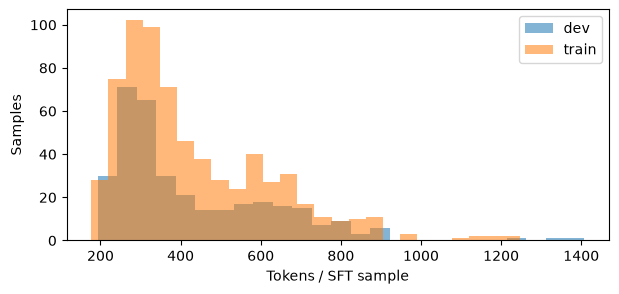

In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_ID)
if not tokenizer.chat_template:
    raise ValueError("Tokenizer chưa có chat template; chọn tokenizer của mô hình chat/instruct.")
SYSTEM = "Giải bài toán vật lý. Trả JSON gồm answer (không kèm đơn vị), unit và explanation."

def sft_text(row):
    target = {"answer": row.answer, "unit": row.unit,
              "explanation": row.cot.replace("\\n", "\n")}
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": row.question},
                {"role": "assistant", "content": json.dumps(target, ensure_ascii=False)}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)

token_lengths = pd.DataFrame({"split": data["split"]})
texts = {"question": data["question"].tolist(), "cot": data["cot"].str.replace("\\n", "\n", regex=False).tolist(),
         "sft": [sft_text(row) for row in data.itertuples()]}
for field, values in texts.items():
    token_lengths[field] = [len(ids) for ids in tokenizer(values, add_special_tokens=False)["input_ids"]]
display(length_summary(token_lengths.melt("split", var_name="field", value_name="length")))
display(token_lengths.groupby("split")["sft"].sum().rename("Tổng token SFT").to_frame())
display(pd.DataFrame({n: token_lengths["sft"].gt(n).groupby(data["split"]).mean().mul(100)
                      for n in LIMITS}).rename_axis(columns="Ngưỡng: % mẫu vượt"))
fig, ax = plt.subplots(figsize=(7, 3))
for split, group in token_lengths.groupby("split"):
    ax.hist(group["sft"], bins=25, alpha=.55, label=split)
ax.set(xlabel="Tokens / SFT sample", ylabel="Samples")
ax.legend()
plt.show()


## 5. Dạng đáp án và đơn vị
Phân loại bằng quy tắc đơn giản, cần đọc lại trường hợp đặc biệt. Giữ nguyên đơn vị gốc;
`-`, `—`, `μ`, `µ`, `Ω` được thống kê để xử lý sau, không tự sửa ở notebook này.


In [6]:
NUMBER = r"[+-]?(?:\d+(?:[.,]\d*)?|[.,]\d+)(?:[eE][+-]?\d+)?"
SCIENCE = NUMBER + r"\s*(?:\*|×|x|\\times)\s*10(?:\s*\^\s*\{?[+-]?\d+\}?|[⁰¹²³⁴⁵⁶⁷⁸⁹⁻⁺]+)"

def answer_type(text):
    text = text.strip()
    if not text: return "Rỗng"
    if ";" in text: return "Nhiều phần"
    if re.fullmatch(NUMBER, text) or re.fullmatch(SCIENCE, text): return "Số"
    if re.search(r"[=+*/^()√]|\\(?:frac|sqrt)|\b(?:sqrt|sin|cos|pi)\b|\d", text): return "Biểu thức/khác"
    return "Văn bản/ký hiệu"

data["answer_type"] = data["answer"].map(answer_type)
types = pd.crosstab(data["answer_type"], data["split"])
display(types)
display(types.div(types.sum()).mul(100).round(1).rename_axis("Tỷ lệ (%)"))
units = pd.crosstab(data["unit"].replace("", "(rỗng)"), data["split"])
display(units.loc[units.sum(axis=1).sort_values(ascending=False).index])


split,dev,train
answer_type,,
Biểu thức/khác,15,20
Nhiều phần,4,13
Rỗng,0,1
Số,303,615
Văn bản/ký hiệu,17,28


split,dev,train
Tỷ lệ (%),,
Biểu thức/khác,4.4,3.0
Nhiều phần,1.2,1.9
Rỗng,0.0,0.1
Số,89.4,90.8
Văn bản/ký hiệu,5.0,4.1


split,dev,train
unit,,
N,62,122
V/m,44,92
-,24,52
V,14,48
J,17,34
Ω,14,36
A,16,28
W,14,27
%,9,25


## 6. Chủ đề sơ bộ
Đếm theo từ khóa, **một câu có thể thuộc nhiều nhóm**. Đây không phải nhãn chủ đề chính thức.


In [7]:
patterns = {
    "Coulomb / điện tích": r"coulomb|điện tích|lực điện",
    "Điện trường / điện thế": r"điện trường|điện thế|điện thông",
    "Tụ điện": r"tụ điện|\btụ\b|điện dung",
    "Từ trường / cảm ứng": r"từ trường|từ thông|cảm ứng|solenoid|ống dây|cuộn dây",
    "Mạch điện": r"mạch|xoay chiều|cộng hưởng|cảm kháng|dung kháng",
    "Sai số / đo lường": r"sai số|độ không đảm bảo|phép đo",
}
topics = pd.DataFrame({name: data["question"].str.contains(p, case=False, regex=True)
                       for name, p in patterns.items()})
topics["Chưa khớp từ khóa"] = ~topics.any(axis=1)
display(topics.groupby(data["split"]).sum().T)
display(topics.groupby(data["split"]).mean().mul(100).round(1).T.rename_axis("Tỷ lệ (%)"))


split,dev,train
Coulomb / điện tích,137,269
Điện trường / điện thế,107,235
Tụ điện,97,187
Từ trường / cảm ứng,40,87
Mạch điện,94,201
Sai số / đo lường,15,34
Chưa khớp từ khóa,11,8


split,dev,train
Tỷ lệ (%),,
Coulomb / điện tích,40.4,39.7
Điện trường / điện thế,31.6,34.7
Tụ điện,28.6,27.6
Từ trường / cảm ứng,11.8,12.9
Mạch điện,27.7,29.7
Sai số / đo lường,4.4,5.0
Chưa khớp từ khóa,3.2,1.2


## 7. Mẫu cần xem lại
Thiếu answer/question/cot, ID trùng, nhãn khác nhau và số phần đáp án–đơn vị lệch nhau là các cờ kiểm tra.
Đơn vị ngoài ASCII chỉ là cảnh báo định dạng API về sau. Không kết luận nhãn sai bằng các quy tắc này.


In [8]:
parts = lambda s: s.str.split(";").str.len()
flags = pd.DataFrame({
    "missing_required": empty[["id", "question", "cot", "answer"]].any(axis=1),
    "duplicate_id": quality["duplicate_id"],
    "overlap_train_dev": data["overlap"],
    "different_labels": data["conflict"],
    "part_mismatch": parts(data["answer"]).ne(parts(data["unit"])),
    "unit_non_ascii": data["unit"].str.contains(r"[^\x00-\x7F]"),
})
display(flags.groupby(data["split"]).sum().T)
review = pd.concat([data[["split"] + COLS], flags], axis=1)
display(review.loc[flags.any(axis=1)].sort_values(
    ["missing_required", "different_labels", "overlap_train_dev", "part_mismatch"], ascending=False).head(20))
display(data[["split"] + COLS].sample(min(5, len(data)), random_state=42))


split,dev,train
missing_required,0,1
duplicate_id,0,0
overlap_train_dev,4,0
different_labels,0,2
part_mismatch,0,0
unit_non_ascii,52,99


,split,id,question,cot,answer,unit,missing_required,duplicate_id,overlap_train_dev,different_labels,part_mismatch,unit_non_ascii
192,train,LD111,"Hai điện tích q1 = -1 * 10^-8 * C, q2 = -6 * 1...",1. Nhận diện dữ kiện:\n- Ba điện tích điểm q1 ...,,,True,False,False,False,False,False
552,train,LD061,"Hai điện tích q1 = q2 = 5 * 10^-16 * C, đặt tạ...",1. Nhận diện dữ kiện:\n- Hai điện tích điểm q1...,1.2178 * 10^-3,V/m,False,False,False,True,False,False
673,train,DT051,"Hai điện tích q1 = q2 = 5 * 10^-16 * C, đặt tạ...",1. Nhận diện dữ kiện:\n- Hai điện tích điểm q1...,1.22 * 10^-3,N/C,False,False,False,True,False,False
739,dev,LD243,Ba điện tích giống nhau q = -3 * 10^-8 * C đặt...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,5.09 * 10^-4,N,False,False,True,False,False,False
740,dev,LD277,Ba điện tích giống nhau q = + 5 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích điểm giố...,31.82,N,False,False,True,False,False,False
787,dev,LD308,Ba điện tích giống nhau q = 1.2 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,5.65*10^6,V/m,False,False,True,False,False,False
834,dev,LD311,Ba điện tích q1 = q2 = q3 = 1.2 * 10^-6 * C đặ...,1. Nhận diện dữ kiện:\n- Ba điện tích giống nh...,1.76*10^6,V/m,False,False,True,False,False,False
4,train,THCB071,"Trong mạch điện, nếu điện trở nhánh D_2 bị giả...",1. Nhận diện dữ kiện:\n- Điện trở nhánh D_2 gi...,Điện trở giảm → dòng tăng,—,False,False,False,False,False,True
15,train,CH020,"Tại cộng hưởng, tổng trở của mạch đo được Z=30...","1. Nhận diện dữ kiện:\n- Tại cộng hưởng, tổng ...",300,Ω,False,False,False,False,False,True
32,train,CH226,Mạch A_B gồm R1 = 20 Ω và một đoạn M_B (R2 + L...,1. Nhận diện dữ kiện:\n- Mạch A_B gồm R1 nối t...,50,Ω,False,False,False,False,False,True


,split,id,question,cot,answer,unit
753,dev,LD103,"Hai điện tích q1 = -4 * 10^-8 * C, q2 = -9 * 1...",1. Nhận diện dữ kiện:\n- Ba điện tích điểm q1 ...,1.48 * 10^-3,N
519,train,TD030,Một tụ điện phẳng có điện dung 21.96 pF được t...,1. Nhận diện dữ kiện:\n- Điện dung C = 21.96 p...,0.63,nC
210,train,NL081,"Một tụ điện có C = 100 μF, U = 50 V. Tính năng...",1. Nhận diện dữ kiện:\n- Điện dung tụ C = 100 ...,125.00,mJ
943,dev,DT029,"Cho hai điện tích q1 = 9.10-8 * C, q2 = -16.10...",1. Nhận diện dữ kiện:\n- q1 = 9 * 10^-8 * C tạ...,36,cm
915,dev,TD366,Một tụ điện có điện tích 30 μC và điện dung 6 ...,1. Nhận diện dữ kiện:\n- Điện tích của tụ: Q =...,5,V


**Sau khảo sát:** xác định mẫu cần kiểm tra, cách chuẩn hóa đầu ra và độ dài huấn luyện.
Giữ nguyên split chính thức. Đổi tokenizer thì chạy lại thống kê token.
